In [192]:
import pandas as pd
import numpy as np
import openpyxl
from pandas import DataFrame, Series
import matplotlib.pyplot as plt
plt.style.use("default")
import gurobipy as gp
from gurobipy import GRB

The following **data** is used for the problem.


In [193]:
suppliers = ["Unit 1", "Unit 2", "Unit 3", "Unit 4", "Unit 5", "Unit 6", "Unit 7", "Unit 8", "Unit 9", "Unit 10"]

raw_unit_data = {
        "energy": ["coal", "coal", "natural gas", "natural gas", "natural gas", "natural gas", "wind", "wind", "solar", "solar"],
        "initial" : [400, 350, 205, 52, 155, 150, 78, 76, 0, 0],
        "initial_up_time" : [6, 5, 3, 1, 2, 2, 1, 1, 0, 0],
        "initial_down_time" : [0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
        "min_gen": [100, 140, 78, 52, 54.25, 39, 17.4, 15.2, 4, 2.4],
        "max_gen": [425, 365, 220, 210, 165, 158, 90, 87, 20, 12],
        "min_uptime": [15, 15, 6, 5, 5, 4, 3, 3, 1, 1],
        "min_downtime":[9, 8, 7, 4, 3, 2, 2, 2, 1, 1],
        "ramp_up":   [212, 150, 101.2, 94.8, 58, 50, 40, 60, 20, 12],
        "ramp_down": [183, 198, 95.6, 101.7, 77.5, 60, 24, 45, 20, 12],
        "start_cost": [5000, 4550, 1320, 1291, 1280, 1105, 560, 554, 300, 250],
        "fixed_cost": [208.61, 117.37, 174.12, 172.75, 95.353, 144.52, 54.417, 54.551, 79.638, 16.259],
        "variable_cost": [22.536, 31.985, 70.5, 69, 32.146, 54.84, 40.222, 40.522, 116.33, 76.642]
}

df_units = DataFrame(raw_unit_data, index=suppliers)

initial_u = {i: int(df_units.loc[i, "initial"] > 0) for i in suppliers}

df_units

,energy,initial,initial_up_time,initial_down_time,min_gen,max_gen,min_uptime,min_downtime,ramp_up,ramp_down,start_cost,fixed_cost,variable_cost
Unit 1,coal,400,6,0,100,425,15,9,212,183,5000,209,23
Unit 2,coal,350,5,0,140,365,15,8,150,198,4550,117,32
Unit 3,natural gas,205,3,0,78,220,6,7,101,96,1320,174,70
Unit 4,natural gas,52,1,0,52,210,5,4,95,102,1291,173,69
Unit 5,natural gas,155,2,0,54,165,5,3,58,78,1280,95,32
Unit 6,natural gas,150,2,0,39,158,4,2,50,60,1105,145,55
Unit 7,wind,78,1,0,17,90,3,2,40,24,560,54,40
Unit 8,wind,76,1,0,15,87,3,2,60,45,554,55,41
Unit 9,solar,0,0,1,4,20,1,1,20,20,300,80,116
Unit 10,solar,0,0,1,2,12,1,1,12,12,250,16,77


In [194]:
raw_demand = [872,861,869,896,947,1028,1128,1226,1321,1387,1427,1440,1433,1437,1437,1431,1411,1366,1302,1238,1184,1117,1043,981,
898,879,881,905,954,1035,1138,1234,1324,1390,1433,1440,1432,1434,1432,1422,1404,1360,1295,1228,1167,1093,1012,945,
899,879,881,905,954,1036,1138,1233,1324,1390,1433,1441,1433,1435,1433,1423,1405,1362,1296,1229,1168,1094,1014,946,
899,880,883,906,956,1037,1140,1235,1326,1393,1436,1443,1435,1437,1435,1425,1407,1363,1298,1230,1170,1096,1015,948,
910,890,892,919,969,1048,1151,1243,1333,1401,1443,1448,1437,1439,1434,1422,1408,1360,1291,1218,1157,1079,998,932,
825,804,807,834,877,921,950,992,1040,1076,1098,1102,1097,1098,1097,1091,1082,1059,1017,968,937,916,843,761,
691,656,643,656,684,729,785,837,895,943,973,988,994,998,1000,1000,996,974,927,869,814,760,704,659]

reserve = [1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1]

# from load_excel_data import load_case_study

# suppliers, raw_unit_data, raw_demand = load_case_study("/Users/vanessahagelskjaer/Downloads/100 unit case study data.xlsx", n_units=50)

# raw_demand = [x * 0.8 for x in raw_demand]

periods = len(raw_demand)
time = range(periods)

extented_time = range(-1, periods)

demand = Series(raw_demand, index = range(1, periods+1))

df_units = DataFrame(raw_unit_data, index=suppliers)

initial_u = {i: int(df_units.loc[i, "initial"] > 0) for i in suppliers}


Next up the problem is defined.

In [195]:
model = gp.Model("production")

The **variables** are added.

In [196]:
u = model.addVars(suppliers, time, vtype=GRB.BINARY, name="u")
y = model.addVars(suppliers, time, vtype=GRB.BINARY, name="y")
z = model.addVars(suppliers, time, vtype=GRB.BINARY, name="z")

q = model.addVars(suppliers, time, vtype=GRB.CONTINUOUS, lb=0, name="q")

The **constraints** are added.

In [197]:
model.addConstrs((gp.quicksum(q[i,t] for i in suppliers) == raw_demand[t] for t in time), name="Market clearing")

model.addConstrs(df_units.loc[i, "min_gen"] * u[i, t] <= q[i,t] for i in suppliers for t in time)
model.addConstrs(df_units.loc[i, "max_gen"] * u[i, t] >= q[i,t] for i in suppliers for t in time)

model.addConstrs(gp.quicksum(df_units.loc[i, "max_gen"] * u[i, t] for i in suppliers) >= reserve[t] * raw_demand[t] for t in time)

model.addConstrs(q[i, t] - q[i, t-1] <= df_units.loc[i, "ramp_up"] for i in suppliers for t in range(1, periods))

model.addConstrs(q[i, t-1] - q[i, t] <= df_units.loc[i, "ramp_down"] for i in suppliers for t in range(1, periods))

model.addConstrs((gp.quicksum(u[i, tau] for tau in range(t, t + int(df_units.loc[i, "min_uptime"]))) >= df_units.loc[i, "min_uptime"] * y[i, t] for i in suppliers
                  for t in range(periods - int(df_units.loc[i, "min_uptime"]) + 1)), name="Minimum up time")

model.addConstrs((gp.quicksum((1 - u[i, tau]) for tau in range(t, t + int(df_units.loc[i, "min_downtime"]))) >= df_units.loc[i, "min_downtime"] * z[i, t] for i in
                  suppliers for t in range(periods - int(df_units.loc[i, "min_downtime"]) + 1)), name="Minimum down time")

model.addConstrs(u[i, t] - u[i, t-1] == y[i,t] - z[i,t] for i in suppliers for t in range(1, periods))

model.addConstrs((u[i, 0] - initial_u[i] == y[i, 0] - z[i, 0] for i in suppliers), name="Initial commitment")

model.addConstrs((q[i, 0] - df_units.loc[i, "initial"] <= df_units.loc[i, "ramp_up"] for i in suppliers), name="Initial ramp up")

model.addConstrs((df_units.loc[i, "initial"] - q[i, 0] <= df_units.loc[i, "ramp_down"] for i in suppliers), name="Initial ramp down")

for i in suppliers:
    min_up = int(df_units.loc[i, "min_uptime"])
    min_down = int(df_units.loc[i, "min_downtime"])

    initial = df_units.loc[i, "initial"]
    initial_up = int(df_units.loc[i, "initial_up_time"])
    initial_down = int(df_units.loc[i, "initial_down_time"])

    if initial > 0:
        remaining_up = min_up - initial_up
        for t in range(remaining_up):
            model.addConstr(u[i, t] == 1, name=f"Initial minimum up time_{i}_{t}")
    else:
        remaining_down = min_down - initial_down
        for t in range(remaining_down):
            model.addConstr(u[i, t] == 0, name=f"Initial minimum down time_{i}_{t}")

Set **the objective function** and solve the problem.

In [198]:
model.setObjective(gp.quicksum(df_units.loc[i, "variable_cost"] * q[i, t] + df_units.loc[i, "fixed_cost"] * u[i, t] + df_units.loc[i, "start_cost"] * y[i, t] for i
                               in suppliers for t in time), GRB.MINIMIZE)
model.Params.MIPGap = 0
model.optimize()

print("Status:", model.Status)
print("Solutions available:", model.SolCount)

if model.Status == GRB.INFEASIBLE:
    model.computeIIS()
    model.write("infeasible_model.ilp")

    print("\nConstraints in the IIS:")
    for constr in model.getConstrs():
        if constr.IISConstr:
            print(constr.ConstrName)

    print("\nGeneral constraints and variable bounds may also be involved.")

u_values = {(i, t): u[i, t].X for i in suppliers for t in time}

y_values = {(i, t): y[i, t].X for i in suppliers for t in time}

z_values = {(i, t): z[i, t].X for i in suppliers for t in time}

q_values = {(i, t): q[i, t].X for i in suppliers for t in time}

Set parameter MIPGap to value 0
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 25.6.0 25G72)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
MIPGap  0

Optimize a model with 12054 rows, 6720 columns and 42396 nonzeros (Min)
Model fingerprint: 0x399c1917
Model has 5040 linear objective coefficients
Variable types: 1680 continuous, 5040 integer (5040 binary)
Coefficient statistics:
  Matrix range     [1e+00, 4e+02]
  Objective range  [2e+01, 5e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+03]

Presolve removed 2199 rows and 897 columns
Presolve time: 0.10s
Presolved: 9855 rows, 5823 columns, 36502 nonzeros
Variable types: 1678 continuous, 4145 integer (4145 binary)
Found heuristic solution: objective 6994925.0323
Found heuristic solution: objective 6817980.8494

Root relaxation: objective 6.055032e+06, 2774 iterations, 0.02 seconds (0.04 work units)

    Nodes    |    C

In [199]:
IP_model = gp.Model()

In [200]:
u = IP_model.addVars(suppliers, extented_time, vtype=GRB.CONTINUOUS, lb=0, name="u")
y = IP_model.addVars(suppliers, time, vtype=GRB.CONTINUOUS, lb=0, name="y")
z = IP_model.addVars(suppliers, time, vtype=GRB.CONTINUOUS, lb=0, name="z")
q = IP_model.addVars(suppliers, extented_time, vtype=GRB.CONTINUOUS, lb=0, name="q")

In [201]:
market_clearing = IP_model.addConstrs((gp.quicksum(q[i,t] for i in suppliers) == raw_demand[t] for t in time), name="Market clearing")

IP_model.addConstrs(df_units.loc[i, "min_gen"] * u[i, t] <= q[i,t] for i in suppliers for t in time)
IP_model.addConstrs(df_units.loc[i, "max_gen"] * u[i, t] >= q[i,t] for i in suppliers for t in time)

ramp_up = IP_model.addConstrs(q[i, t] - q[i, t-1] <= df_units.loc[i, "ramp_up"] * u[i,t] for i in suppliers for t in time)

ramp_down = IP_model.addConstrs(q[i, t-1] - q[i, t] <= df_units.loc[i, "ramp_down"] * u[i,t-1] for i in suppliers for t in time)

IP_model.addConstrs(u[i, t] - u[i, t-1] == y[i,t] - z[i,t] for i in suppliers for t in time)

init_u = IP_model.addConstrs(u[i,-1] == initial_u[i] for i in suppliers)

init_q = IP_model.addConstrs(q[i,-1] == df_units.loc[i,"initial"] for i in suppliers)

on_price = IP_model.addConstrs(u[i, t] == u_values[i, t] for i in suppliers for t in time)

turn_on_price = IP_model.addConstrs(y[i, t] == y_values[i, t] for i in suppliers for t in time)

turn_off_price = IP_model.addConstrs(z[i, t] == z_values[i, t] for i in suppliers for t in time)

In [202]:
IP_model.setObjective(gp.quicksum(df_units.loc[i, "variable_cost"] * q[i, t] + df_units.loc[i, "fixed_cost"] * u[i, t] + df_units.loc[i, "start_cost"] * y[i, t] for i
                               in suppliers for t in time), GRB.MINIMIZE)

IP_model.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 25.6.0 25G72)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 13628 rows, 6740 columns and 30260 nonzeros (Min)
Model fingerprint: 0x3fddbdb2
Model has 5040 linear objective coefficients
Coefficient statistics:
  Matrix range     [1e+00, 4e+02]
  Objective range  [2e+01, 5e+03]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+03]

Presolve removed 13262 rows and 6348 columns
Presolve time: 0.01s
Presolved: 366 rows, 559 columns, 1178 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 8.420e+02
 Factor NZ  : 3.833e+03
 Factor Ops : 5.114e+04 (less than 1 second per iteration)
 Threads    : 1

Barrier performed 0 iterations in 0.01 seconds (0.01 work units)
Barrier solve interrupted - model solved by another algorithm


Solv

In [203]:
if IP_model.status == GRB.OPTIMAL:

    print("Optimal fixed-commitment LP found.")
    print("Variable generation cost:", IP_model.objVal)

else:

    print("The LP did not find an optimal solution.")
    print("Gurobi status:", IP_model.status)

if IP_model.status == GRB.OPTIMAL:

    prices = []

    for t in time:

        prices.append({
            "time": t,
            "demand": raw_demand[t],
            "price": market_clearing[t].Pi,
        })


    price_df = pd.DataFrame(prices).set_index("time")

    supplier_price = []

    for t in time:
        for i in suppliers:
            supplier_price.append({
                "supplier": i,
                "time": t,
                "on or off": u[i, t].X,
                "turned on": y[i, t].X,
                "on_price": on_price[i, t].Pi,
                "turn_on_price": turn_on_price[i, t].Pi,
                "turn_off_price": turn_off_price[i, t].Pi,
            })

    supplier_price_df = pd.DataFrame(supplier_price)

    print(price_df.to_string(float_format=lambda x: f"{x:.15f}"))


Optimal fixed-commitment LP found.
Variable generation cost: 6062386.357699992
      demand              price
time                           
0        872 22.536000000000001
1        861 31.984999999999999
2        869 31.984999999999999
3        896 31.984999999999999
4        947 32.307000000000002
5       1028 40.521999999999998
6       1128 40.521999999999998
7       1226 69.158000000000015
8       1321 54.840000000000003
9       1387 69.000000000000000
10      1427 69.000000000000000
11      1440 69.000000000000000
12      1433 69.000000000000000
13      1437 69.000000000000000
14      1437 69.000000000000000
15      1431 69.000000000000000
16      1411 69.000000000000000
17      1366 69.000000000000000
18      1302 76.641999999999996
19      1238 54.840000000000003
20      1184 54.840000000000003
21      1117 56.374000000000002
22      1043 32.146000000000001
23       981 32.146000000000001
24       898 32.146000000000001
25       879 32.146000000000001
26       881 32.146000000

         unit  time  generation  status  startup  shutdown
0      Unit 1     0         306       1        0         0
1      Unit 1     1         425       1        0         0
2      Unit 1     2         425       1        0         0
3      Unit 1     3         425       1        0         0
4      Unit 1     4         425       1        0         0
...       ...   ...         ...     ...      ...       ...
1675  Unit 10   163           0       0        0         0
1676  Unit 10   164           0       0        0         0
1677  Unit 10   165           0       0        0         0
1678  Unit 10   166           0       0        0         0
1679  Unit 10   167           0       0        0         0

[1680 rows x 6 columns]


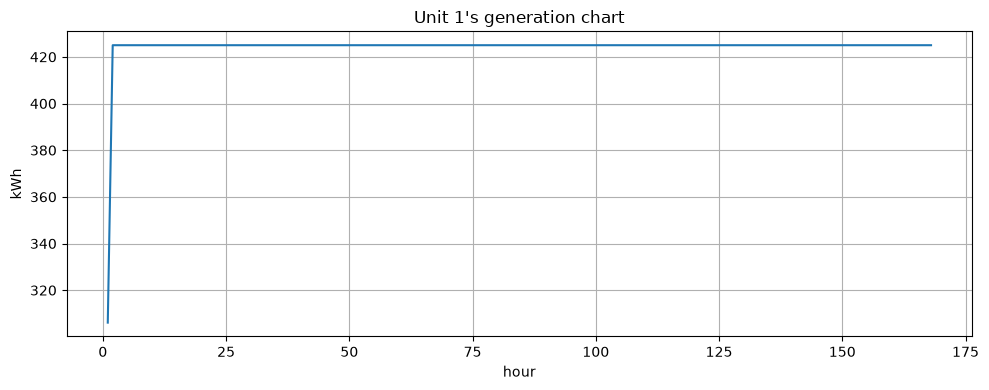

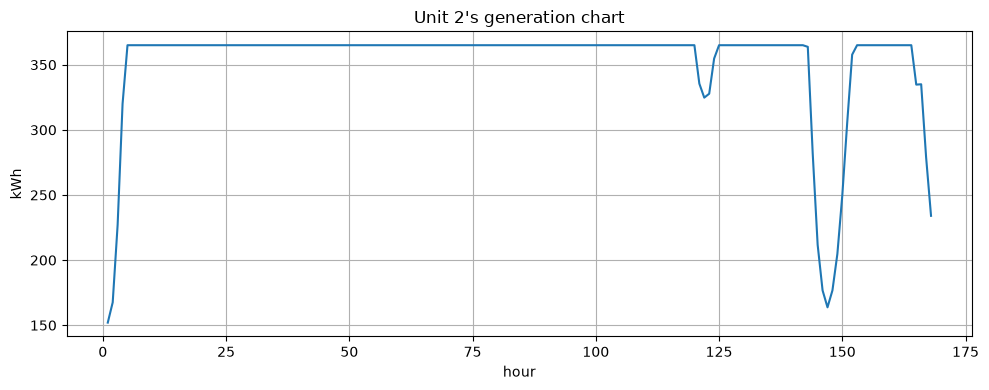

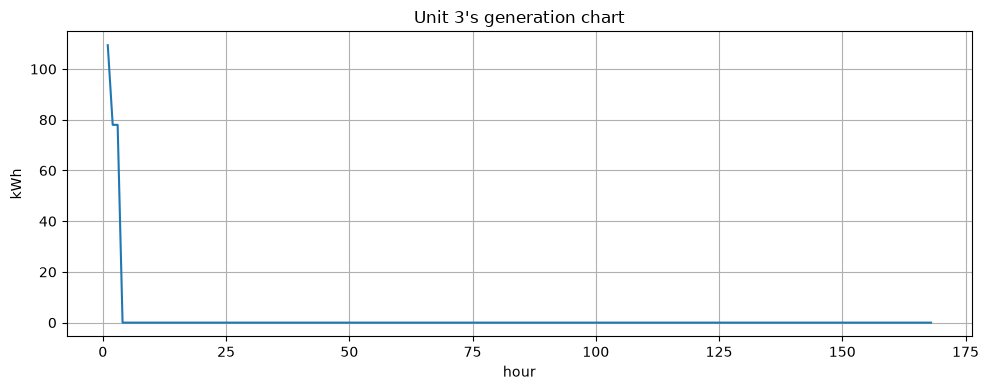

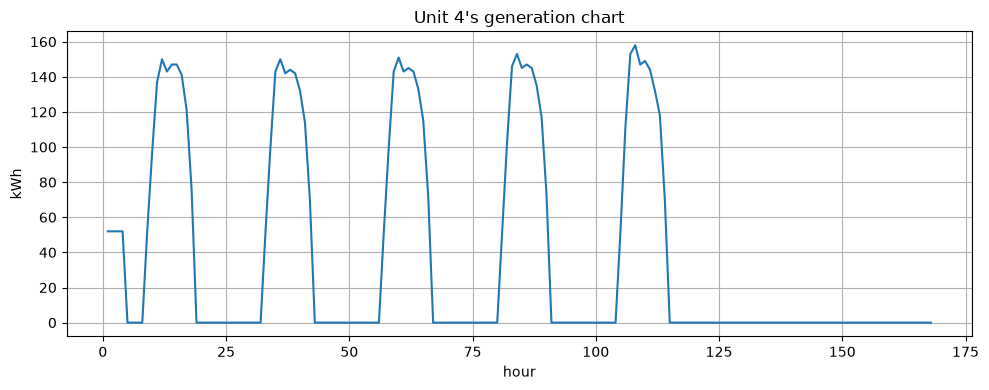

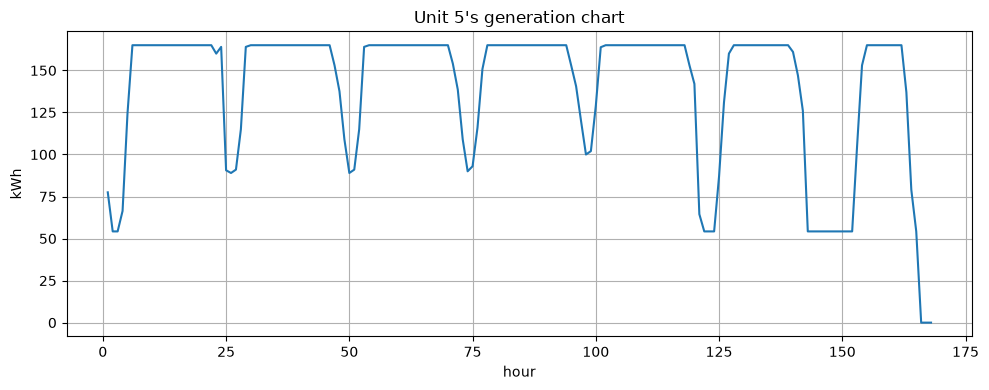

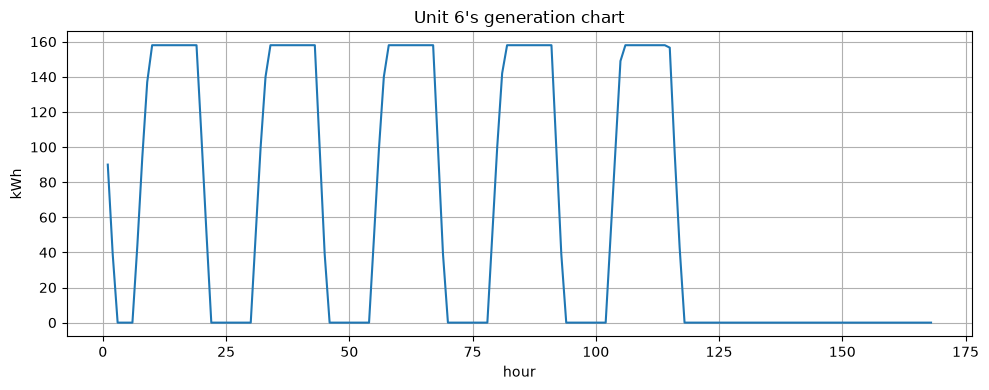

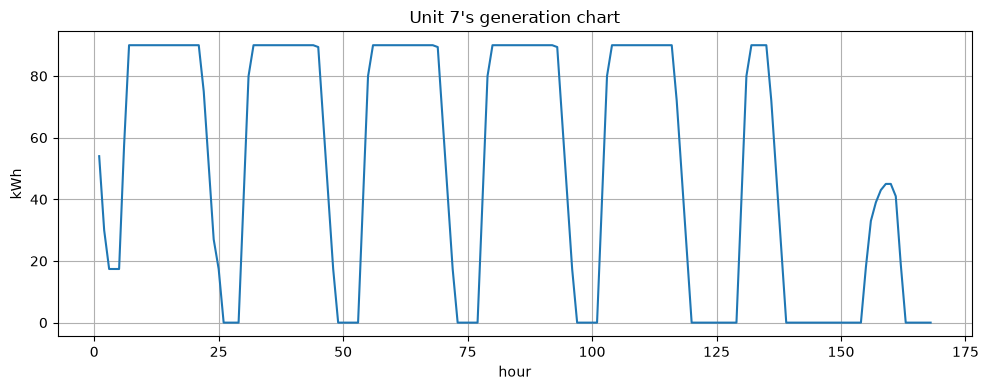

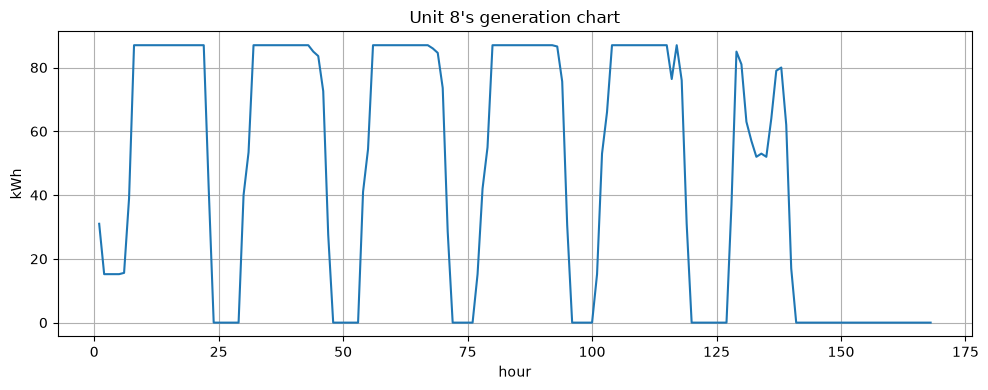

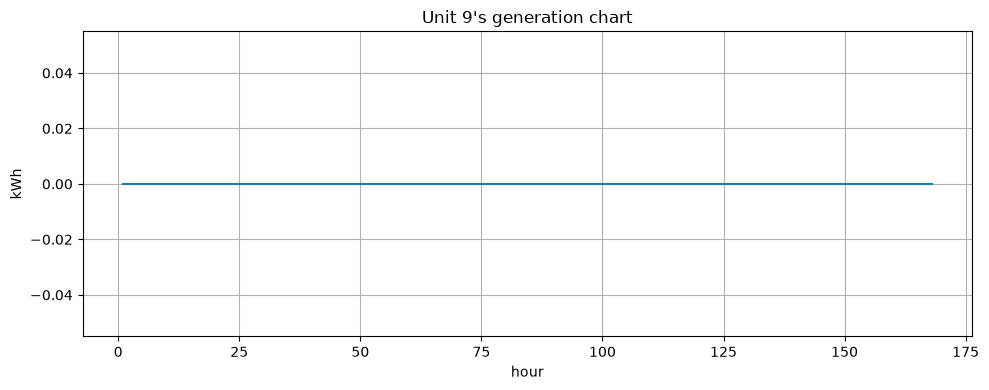

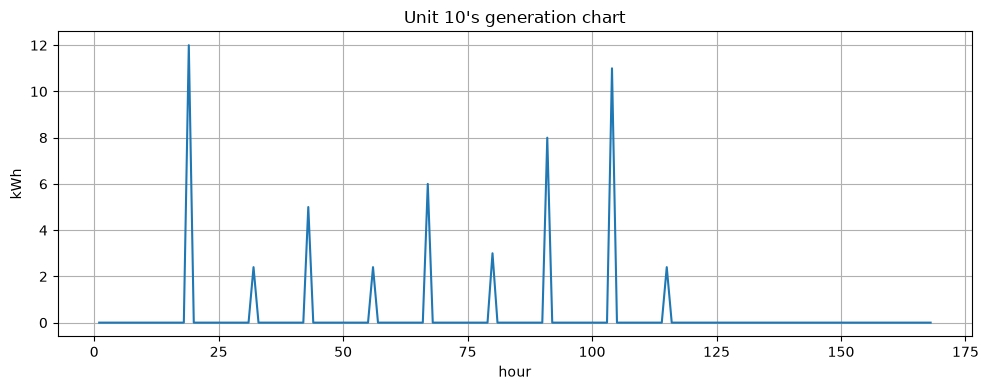

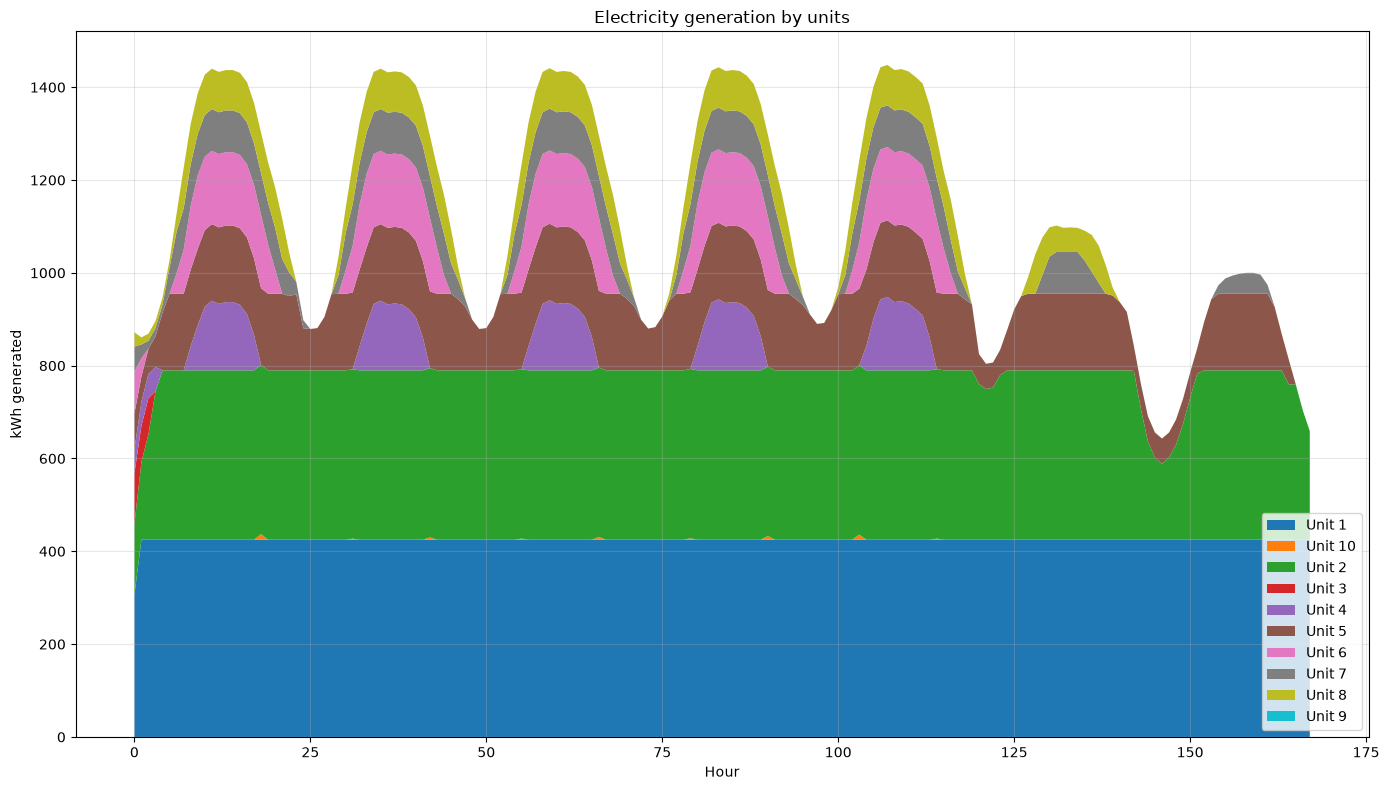

In [204]:
results = []

for i in suppliers:
    for t in time:
        results.append({
            "unit": i,
            "time": t,
            "generation": q[i,t].X,
            "status": round(u[i,t].X),
            "startup": round(y[i,t].X),
            "shutdown": round(z[i,t].X)
        })

    results_df = pd.DataFrame(results)

print(results_df)

for i in suppliers:
    supplier_data = results_df[results_df["unit"] == i]

    plt.figure(figsize=(10, 4))

    plt.plot(
        supplier_data["time"] + 1,
        supplier_data["generation"]
    )

    plt.title(f"{i}'s generation chart")
    plt.xlabel("hour")
    plt.ylabel("kWh")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"Generation chart for unit {i}.png")
    plt.show()

generation_df = results_df.pivot(
    index="time",
    columns="unit",
    values="generation"
)

initial_generation = {
    "Unit 1": 400,
    "Unit 2": 350,
    "Unit 3": 205,
    "Unit 4": 52,
    "Unit 5": 155,
    "Unit 6": 150,
    "Unit 7": 78,
    "Unit 8": 76,
    "Unit 9": 0,
    "Unit 10": 0}

initial_row = pd.DataFrame(
    [initial_generation],
    index=[0]
)

#generation_df = pd.concat([initial_row, generation_df])
generation_df = generation_df.sort_index()

plt.figure(figsize=(14, 8))

plt.stackplot(
    generation_df.index,
    generation_df.T,
    labels=generation_df.columns
)

plt.title("Electricity generation by units")
plt.xlabel("Hour")
plt.ylabel("kWh generated")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.savefig("Generation chart IP.png")
plt.show()

Calculates the **profit of the suppliers** under the found prices and the generation schedule for IP-pricing:

In [205]:
revenue = {}
cost = {}
uplift = {}
profit = {}

for i in suppliers:

    revenue[i] = sum(
        market_clearing[t].Pi * q_values[i, t]
        for t in time
    )

    cost[i] = sum(
        df_units.loc[i, "variable_cost"] * q_values[i, t]
        + df_units.loc[i, "fixed_cost"] * u_values[i, t]
        + df_units.loc[i, "start_cost"] * y_values[i, t]
        for t in time
    )

    uplift[i] = sum(
        on_price[i, t].Pi * u_values[i, t]
        + turn_on_price[i, t].Pi * y_values[i, t]
        + turn_off_price[i, t].Pi * z_values[i, t]
        for t in time
    ) + init_u[i].Pi * initial_u[i] + init_q[i].Pi * df_units.loc[i,"initial"]

    profit[i] = revenue[i] + uplift[i] - cost[i]

pd.set_option("display.float_format", "{:,.0f}".format)

profit_df = pd.DataFrame([
    {
        "supplier": i,
        "revenue": revenue[i],
        "cost": cost[i],
        "uplift": uplift[i],
        "profit": profit[i],
    }
    for i in suppliers
])

price   = {t: market_clearing[t].Pi for t in time}
pi_u    = {(i,t): on_price[i,t].Pi       for i in suppliers for t in time}
pi_y    = {(i,t): turn_on_price[i,t].Pi  for i in suppliers for t in time}
pi_z    = {(i,t): turn_off_price[i,t].Pi for i in suppliers for t in time}

print(profit_df.to_string(float_format=lambda x: f"{x:.2f}"))

  supplier    revenue       cost      uplift  profit
0   Unit 1 3424650.94 1641437.35 -1783213.59    0.00
1   Unit 2 2876867.27 1912420.94  -964446.33   -0.00
2   Unit 3    7455.10   19233.06    11777.96   -0.00
3   Unit 4  419722.93  447378.50    27655.57    0.00
4   Unit 5 1199358.24  774340.27  -425017.97   -0.00
5   Unit 6  670306.03  574847.46   -95458.56    0.00
6   Unit 7  502597.28  354260.40  -148336.88    0.00
7   Unit 8  476408.64  332071.33  -144337.30    0.00
8   Unit 9       0.00       0.00        0.00    0.00
9  Unit 10    3946.83    6397.04     2450.22   -0.00


Profits for IP+-pricing:

In [206]:
revenue = {}
cost = {}
uplift = {}
profit = {}
benchmark = {}
violation = {}

for i in suppliers:

    revenue[i] = sum(
        market_clearing[t].Pi * q_values[i, t]
        for t in time
    )

    cost[i] = sum(
        df_units.loc[i, "variable_cost"] * q_values[i, t]
        + df_units.loc[i, "fixed_cost"] * u_values[i, t]
        + df_units.loc[i, "start_cost"] * y_values[i, t]
        for t in time
    )

    uplift[i] = max(0, sum(
        on_price[i, t].Pi * u_values[i, t]
        + turn_on_price[i, t].Pi * y_values[i, t]
        + turn_off_price[i, t].Pi * z_values[i, t]
        for t in time
    ) + init_u[i].Pi * initial_u[i] + init_q[i].Pi * df_units.loc[i,"initial"])

    profit[i] = revenue[i] + uplift[i] - cost[i]

pd.set_option("display.float_format", "{:,.0f}".format)

profit_df = pd.DataFrame([
    {
        "supplier": i,
        "revenue": revenue[i],
        "cost": cost[i],
        "uplift": uplift[i],
        "profit": profit[i],

    }
    for i in suppliers
])

print(profit_df.to_string(float_format=lambda x: f"{x:.2f}"))


  supplier    revenue       cost   uplift     profit
0   Unit 1 3424650.94 1641437.35     0.00 1783213.60
1   Unit 2 2876867.27 1912420.94     0.00  964446.33
2   Unit 3    7455.10   19233.06 11777.96      -0.00
3   Unit 4  419722.93  447378.50 27655.57       0.00
4   Unit 5 1199358.24  774340.27     0.00  425017.97
5   Unit 6  670306.03  574847.46     0.00   95458.57
6   Unit 7  502597.28  354260.40     0.00  148336.88
7   Unit 8  476408.64  332071.33     0.00  144337.30
8   Unit 9       0.00       0.00     0.00       0.00
9  Unit 10    3946.83    6397.04  2450.22      -0.00


The following the the profit max problem:

In [207]:
profit_model = gp.Model()

In [208]:
u = profit_model.addVars(suppliers, time, vtype=GRB.BINARY, name="u")
y = profit_model.addVars(suppliers, time, vtype=GRB.BINARY, name="y")
z = profit_model.addVars(suppliers, time, vtype=GRB.BINARY, name="z")

q = profit_model.addVars(suppliers, time, vtype=GRB.CONTINUOUS, lb=0, name="q")

In [209]:
profit_model.addConstrs(df_units.loc[i, "min_gen"] * u[i, t] <= q[i,t] for i in suppliers for t in time)
profit_model.addConstrs(df_units.loc[i, "max_gen"] * u[i, t] >= q[i,t] for i in suppliers for t in time)

profit_model.addConstrs(gp.quicksum(df_units.loc[i, "max_gen"] * u[i, t] for i in suppliers) >= reserve[t] * raw_demand[t] for t in time)

profit_model.addConstrs(q[i, t] - q[i, t-1] <= df_units.loc[i, "ramp_up"] for i in suppliers for t in range(1, periods))

profit_model.addConstrs(q[i, t-1] - q[i, t] <= df_units.loc[i, "ramp_down"] for i in suppliers for t in range(1, periods))

profit_model.addConstrs((gp.quicksum(u[i, tau] for tau in range(t, t + int(df_units.loc[i, "min_uptime"]))) >= df_units.loc[i, "min_uptime"] * y[i, t] for i in suppliers
                  for t in range(periods - int(df_units.loc[i, "min_uptime"]) + 1)), name="Minimum up time")

profit_model.addConstrs((gp.quicksum((1 - u[i, tau]) for tau in range(t, t + int(df_units.loc[i, "min_downtime"]))) >= df_units.loc[i, "min_downtime"] * z[i, t] for i in
                  suppliers for t in range(periods - int(df_units.loc[i, "min_downtime"]) + 1)), name="Minimum down time")

profit_model.addConstrs(u[i, t] - u[i, t-1] == y[i,t] - z[i,t] for i in suppliers for t in range(1, periods))

profit_model.addConstrs((u[i, 0] - initial_u[i] == y[i, 0] - z[i, 0] for i in suppliers), name="Initial commitment")

profit_model.addConstrs((q[i, 0] - df_units.loc[i, "initial"] <= df_units.loc[i, "ramp_up"] for i in suppliers), name="Initial ramp up")

profit_model.addConstrs((df_units.loc[i, "initial"] - q[i, 0] <= df_units.loc[i, "ramp_down"] for i in suppliers), name="Initial ramp down")

for i in suppliers:
    min_up = int(df_units.loc[i, "min_uptime"])
    min_down = int(df_units.loc[i, "min_downtime"])

    initial = df_units.loc[i, "initial"]
    initial_up = int(df_units.loc[i, "initial_up_time"])
    initial_down = int(df_units.loc[i, "initial_down_time"])

    if initial > 0:
        remaining_up = min_up - initial_up
        for t in range(remaining_up):
            profit_model.addConstr(u[i, t] == 1, name=f"Initial minimum up time_{i}_{t}")
    else:
        remaining_down = min_down - initial_down
        for t in range(remaining_down):
            profit_model.addConstr(u[i, t] == 0, name=f"Initial minimum down time_{i}_{t}")

In [210]:
price_values = {t: market_clearing[t].Pi for t in time}

profit_model.setObjective(
    gp.quicksum(price_values[t] * q[i, t] - df_units.loc[i, "variable_cost"] * q[i, t] - df_units.loc[i, "fixed_cost"] * u[i, t] - df_units.loc[i, "start_cost"] * y[i, t] for t in time), GRB.MAXIMIZE)

profit_model.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 25.6.0 25G72)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 11886 rows, 6720 columns and 40716 nonzeros (Max)
Model fingerprint: 0x49b10599
Model has 498 linear objective coefficients
Variable types: 1680 continuous, 5040 integer (5040 binary)
Coefficient statistics:
  Matrix range     [1e+00, 4e+02]
  Objective range  [7e+00, 2e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+03]

Presolve removed 8194 rows and 2985 columns
Presolve time: 0.08s
Presolved: 3692 rows, 3735 columns, 18395 nonzeros
Variable types: 0 continuous, 3735 integer (3735 binary)
Found heuristic solution: objective -0.0000000

Explored 0 nodes (0 simplex iterations) in 0.09 seconds (0.20 work units)
Thread count was 8 (of 8 available processors)

Solution count 1: -0 
No other solutions better than -0

Optimal solution found (tolerance 1.00e-04)
Best ob

In [211]:
profit_results = {}
q_results = {}
u_results = {}
y_results = {}
z_results = {}

price_values = {
    t: market_clearing[t].Pi
    for t in time
}

for i in suppliers:

    print(f"\nSolving profit problem for supplier {i}...")

    profit_model = gp.Model(f"Profit_Model_{i}")

    u = profit_model.addVars(time, vtype=GRB.BINARY, name=f"u_{i}")
    y = profit_model.addVars(time, vtype=GRB.BINARY, name=f"y_{i}")
    z = profit_model.addVars(time, vtype=GRB.BINARY, name=f"z_{i}")

    q = profit_model.addVars(time, vtype=GRB.CONTINUOUS, lb=0, name=f"q_{i}")

    profit_model.addConstrs(df_units.loc[i, "min_gen"] * u[t] <= q[t] for t in time)
    profit_model.addConstrs(q[t] <= df_units.loc[i, "max_gen"] * u[t] for t in time)

    profit_model.addConstrs(q[t] - q[t-1] <= df_units.loc[i, "ramp_up"] for t in range(1, periods))

    profit_model.addConstrs(q[t-1] - q[t] <= df_units.loc[i, "ramp_down"] for t in range(1, periods))

    min_up = int(df_units.loc[i, "min_uptime"])

    profit_model.addConstrs(gp.quicksum(u[tau] for tau in range(t, t + min_up)) >= min_up * y[t] for t in range(periods - min_up + 1))

    min_down = int(df_units.loc[i, "min_downtime"])

    profit_model.addConstrs(gp.quicksum(1 - u[tau] for tau in range(t, t + min_down)) >= min_down * z[t] for t in range(periods - min_down + 1))

    profit_model.addConstrs(u[t] - u[t-1] == y[t] - z[t] for t in range(1, periods))

    profit_model.addConstr(u[0] - initial_u[i] == y[0] - z[0], name=f"Initial_commitment_{i}")

    profit_model.addConstr(q[0] - df_units.loc[i, "initial"] <= df_units.loc[i, "ramp_up"], name=f"Initial_ramp_up_{i}")

    profit_model.addConstr(df_units.loc[i, "initial"] - q[0] <= df_units.loc[i, "ramp_down"], name=f"Initial_ramp_down_{i}")

    initial = df_units.loc[i, "initial"]
    initial_up = int(df_units.loc[i, "initial_up_time"])
    initial_down = int(df_units.loc[i, "initial_down_time"])

    if initial > 0:
        remaining_up = min_up - initial_up
        for t in range(max(0, remaining_up)):
            profit_model.addConstr(u[t] == 1, name=f"Initial_minimum_up_time_{i}_{t}")

    else:
        remaining_down = min_down - initial_down
        for t in range(max(0, remaining_down)):
            profit_model.addConstr(u[t] == 0, name=f"Initial_minimum_down_time_{i}_{t}")

    profit_model.setObjective(
        gp.quicksum(price_values[t] * q[t] - df_units.loc[i, "variable_cost"] * q[t] - df_units.loc[i, "fixed_cost"] * u[t] - df_units.loc[i, "start_cost"] * y[t] for t in time), GRB.MAXIMIZE)

    profit_model.optimize()

    if profit_model.status == GRB.OPTIMAL:

        profit_results[i] = profit_model.ObjVal

        q_results[i] = {t: q[t].X for t in time}

        u_results[i] = {t: u[t].X for t in time}

        y_results[i] = {t: y[t].X for t in time}

        z_results[i] = {t: z[t].X for t in time}

        print(f"Supplier {i}: optimal profit = {profit_model.ObjVal:.2f}")

    else:
        profit_results[i] = None
        print(f"Supplier {i}: no optimal solution found. Gurobi status = {profit_model.status}")


Solving profit problem for supplier Unit 1...
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 25.6.0 25G72)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 1163 rows, 672 columns and 6086 nonzeros (Max)
Model fingerprint: 0xf99dbcd0
Model has 503 linear objective coefficients
Variable types: 168 continuous, 504 integer (504 binary)
Coefficient statistics:
  Matrix range     [1e+00, 4e+02]
  Objective range  [9e+00, 5e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 6e+02]

Found heuristic solution: objective 38195.638000
Presolve removed 241 rows and 44 columns
Presolve time: 0.02s
Presolved: 922 rows, 628 columns, 6019 nonzeros
Found heuristic solution: objective 52586.044000
Variable types: 161 continuous, 467 integer (467 binary)

Root relaxation: objective 1.783214e+06, 0 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds 

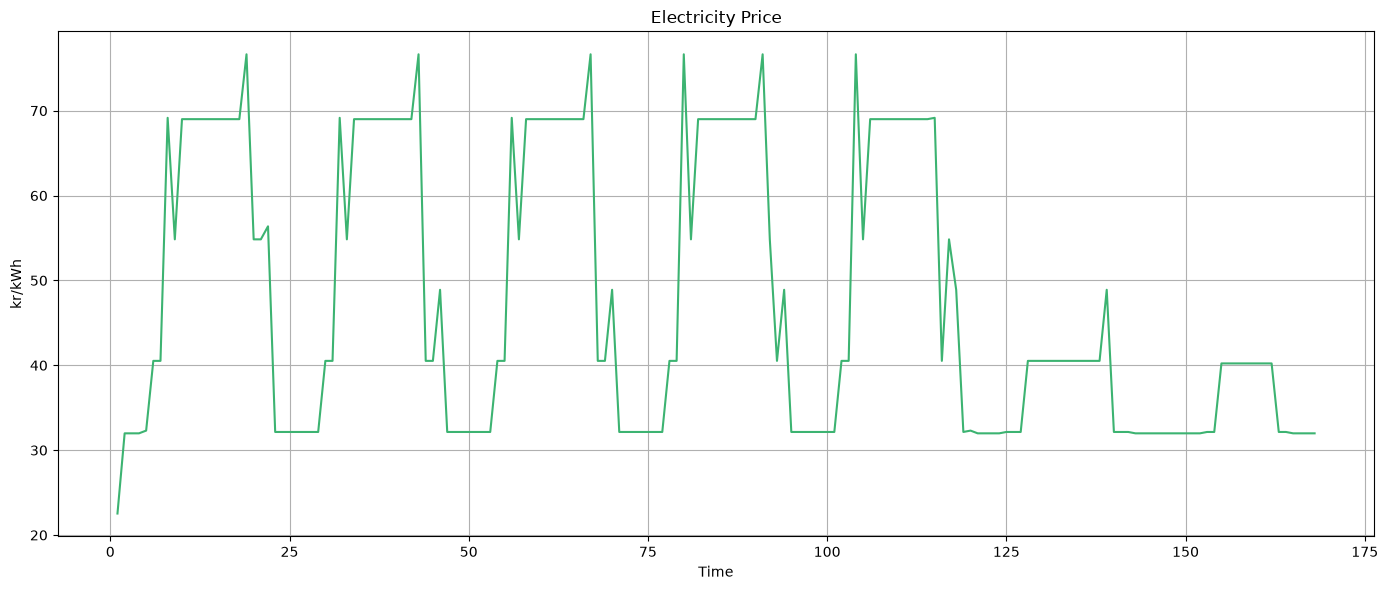

     time  demand  price
0       0     872     23
1       1     861     32
2       2     869     32
3       3     896     32
4       4     947     32
..    ...     ...    ...
163   163     869     32
164   164     814     32
165   165     760     32
166   166     704     32
167   167     659     32

[168 rows x 3 columns]


In [212]:
if IP_model.status == GRB.OPTIMAL:

    prices = []

    for t in time:

        prices.append({
            "time": t,
            "demand": raw_demand[t],
            "price": market_clearing[t].Pi
        })


    price_df = pd.DataFrame(prices)

    plt.figure(figsize=(14, 6))

    plt.plot(price_df["time"] + 1, price_df["price"], color="mediumseagreen")
    plt.title("Electricity Price")
    plt.xlabel("Time")
    plt.ylabel("kr/kWh")
    plt.grid(True)

    plt.tight_layout()
    plt.savefig("Price_IP_pricing.png")
    plt.show()

    print(price_df)

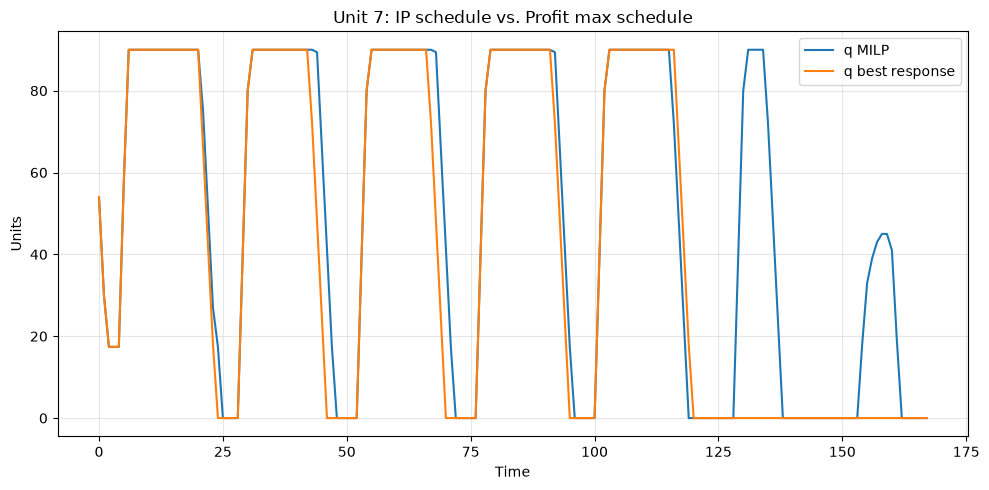

In [215]:
i = "Unit 7"
diff = [(t, round(u_values[i,t]), round(u_results[i][t]),
         round(q_values[i,t],1), round(q_results[i][t],1), round(price_values[t],2))
        for t in time if abs(q_values[i,t]-q_results[i][t]) > 1e-6]

i = "Unit 7"

q_milp = [q_values[i, t] for t in time]
q_best_resp = [q_results[i][t] for t in time]

plt.figure(figsize=(10, 5))
plt.plot(time, q_milp, label="q MILP")
plt.plot(time, q_best_resp, label="q best response")

plt.xlabel("Time")
plt.ylabel("Units")
plt.title(f"{i}: IP schedule vs. Profit max schedule")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()